# Apple Health export.zip to pandas

Reads the file the iPhone Health app writes with **Export All Health Data** (Apple's iPhone User Guide: "You can export all of your health and fitness data from Health in XML format"), streams its `Record` and `Workout` elements into pandas DataFrames, and charts three things: daily steps, resting heart rate and nightly sleep.

**The input here is synthetic.** It is `apple-health-export-synthetic.zip` from [https://aifitnessapi.com/own-your-data](https://aifitnessapi.com/own-your-data#notebooks): 120 made-up days from a "Synthetic Watch", a "Synthetic Phone" and a "Synthetic Scale App", generated from a fixed seed. Point `EXPORT` at your own `export.zip` (or the `export.xml` inside it) to run it on your data, which never leaves your machine.

Apple publishes no schema for `export.xml` that we could find, so this notebook reads elements and attributes by the names the file uses (`Record`, `type`, `sourceName`, `unit`, `startDate`, `endDate`, `value`). Only pandas, matplotlib and the standard library are used.

In [1]:
import os, urllib.request

def local_or_download(path, url):
    """Use the file next to this notebook if it is there (a clone of the repo),
    otherwise download the synthetic sample once (Colab)."""
    if os.path.exists(path):
        return path
    name = os.path.basename(path)
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)
    return name

# Your export: a path to export.zip or export.xml.
EXPORT = local_or_download("../samples/apple-health-export-synthetic.zip",
                           "https://aifitnessapi.com/samples/apple-health-export-synthetic.zip")
EXPORT

'../samples/apple-health-export-synthetic.zip'

## Stream the XML

`iterparse` hands over one element at a time and `elem.clear()` frees it, so memory stays flat even for an export of hundreds of megabytes. Inside a ZIP, the file to read is the shallowest one named `export.xml`.

In [2]:
import zipfile
import xml.etree.ElementTree as ET
import pandas as pd

def open_export(path):
    if path.lower().endswith(".zip"):
        z = zipfile.ZipFile(path)
        names = [n for n in z.namelist() if n.split("/")[-1].lower() == "export.xml"]
        return z.open(min(names, key=lambda n: n.count("/")))
    return open(path, "rb")

RECORD_COLS = ["type", "sourceName", "unit", "startDate", "endDate", "value"]
WORKOUT_COLS = ["workoutActivityType", "sourceName", "duration", "durationUnit", "startDate", "endDate"]
records, workouts = [], []
with open_export(EXPORT) as f:
    for _, elem in ET.iterparse(f, events=("end",)):
        if elem.tag == "Record":
            records.append([elem.get(c) for c in RECORD_COLS])
            elem.clear()
        elif elem.tag == "Workout":
            workouts.append([elem.get(c) for c in WORKOUT_COLS])
            elem.clear()

df = pd.DataFrame(records, columns=RECORD_COLS)
wo = pd.DataFrame(workouts, columns=WORKOUT_COLS)
print(f"{len(df):,} records, {len(wo):,} workouts")

12,880 records, 69 workouts


## Dates: keep the day where it happened

Each timestamp is written with its UTC offset, for example `2026-06-01 07:13:00 -0700`. The first ten characters are the local calendar day, which is the day a person means by "Monday's steps". Converting to UTC first would push late-evening samples into the next day, so the day comes straight from the string.

In [3]:
for frame in (df, wo):
    frame["start"] = pd.to_datetime(frame["startDate"], format="%Y-%m-%d %H:%M:%S %z", utc=True)
    frame["end"] = pd.to_datetime(frame["endDate"], format="%Y-%m-%d %H:%M:%S %z", utc=True)
    frame["day"] = pd.to_datetime(frame["startDate"].str[:10])
df["num"] = pd.to_numeric(df["value"], errors="coerce")
df["short"] = df["type"].str.replace(r"^HK(Quantity|Category)TypeIdentifier", "", regex=True)

summary = (df.groupby("short")
             .agg(rows=("type", "size"), first=("day", "min"), last=("day", "max"),
                  units=("unit", lambda u: ", ".join(sorted(set(u.dropna())))),
                  sources=("sourceName", "nunique"))
             .sort_values("rows", ascending=False))
summary

,rows,first,last,units,sources
short,,,,,
HeartRate,6120,2026-06-01,2026-09-28,count/min,1
ActiveEnergyBurned,1800,2026-06-01,2026-09-28,kcal,1
DistanceWalkingRunning,1800,2026-06-01,2026-09-28,km,1
StepCount,1800,2026-06-01,2026-09-28,count,2
SleepAnalysis,1080,2026-05-31,2026-09-28,,1
RestingHeartRate,120,2026-06-01,2026-09-28,count/min,1
HeartRateVariabilitySDNN,120,2026-06-01,2026-09-28,ms,1
BodyMass,40,2026-06-01,2026-09-26,kg,1


## Daily steps, and the double-count trap

Steps can arrive from more than one source. When a phone in a pocket and a watch on the wrist both count the same walk, summing every row adds the two counts together. HealthKit's statistics queries are built to merge overlapping sources; a raw export is not, so look at the sources side by side before trusting a sum. In this synthetic file the phone and watch rows cover different hours, so the sum happens to be right; check your own file the same way.

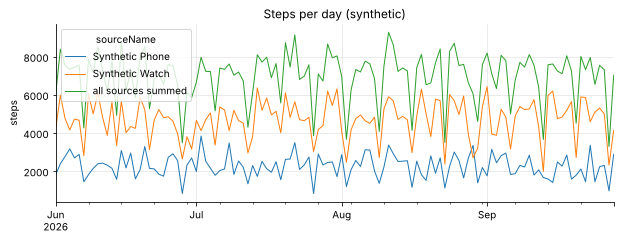

sourceName,Synthetic Phone,Synthetic Watch,all sources summed
count,120.0,120.0,120.0
mean,2274.0,4698.0,6973.0
std,607.0,1021.0,1298.0
min,838.0,1996.0,3301.0
25%,1827.0,4140.0,6553.0
50%,2268.0,4829.0,7290.0
75%,2704.0,5380.0,7715.0
max,3849.0,6437.0,9290.0


In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 72})

steps = df[df["type"] == "HKQuantityTypeIdentifierStepCount"]
by_source = steps.pivot_table(index="day", columns="sourceName", values="num", aggfunc="sum").fillna(0)
by_source["all sources summed"] = by_source.sum(axis=1)
ax = by_source.plot(title="Steps per day (synthetic)", lw=1)
ax.set_ylabel("steps"); ax.set_xlabel("")
plt.show()
by_source.describe().round(0)

## Resting heart rate and nightly sleep

Resting heart rate is one value per day here, so a 7-day rolling mean shows the trend. Sleep is a category type: each row is a stretch of time with a stage in `value`. Summing the stretches whose value starts with `HKCategoryValueSleepAnalysisAsleep` gives hours asleep. A night straddles midnight, so each stretch is assigned to a night by shifting its local start time forward 12 hours and taking the date: a stretch starting at 23:00 or at 02:00 both land on the morning the night ended.

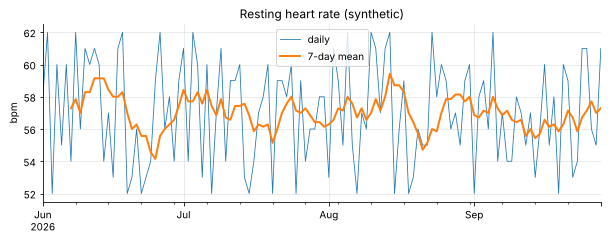

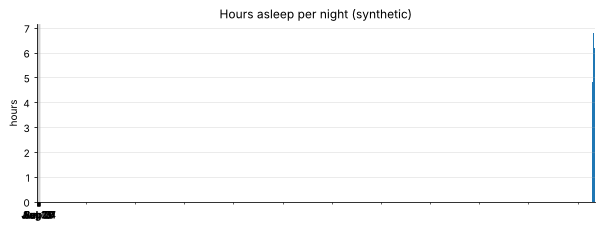

count    120.00
mean       5.55
std        0.57
min        3.85
25%        5.20
50%        5.55
75%        5.97
max        6.80
Name: hours, dtype: float64

In [5]:
rhr = (df[df["type"] == "HKQuantityTypeIdentifierRestingHeartRate"]
       .groupby("day")["num"].mean())
ax = rhr.plot(lw=0.8, label="daily", title="Resting heart rate (synthetic)")
rhr.rolling(7).mean().plot(ax=ax, lw=2, label="7-day mean")
ax.set_ylabel("bpm"); ax.set_xlabel(""); ax.legend()
plt.show()

sleep = df[(df["type"] == "HKCategoryTypeIdentifierSleepAnalysis")
           & df["value"].str.startswith("HKCategoryValueSleepAnalysisAsleep")].copy()
sleep["hours"] = (sleep["end"] - sleep["start"]).dt.total_seconds() / 3600
sleep["night"] = (pd.to_datetime(sleep["startDate"].str[:19]) + pd.Timedelta(hours=12)).dt.normalize()
per_night = sleep.groupby("night")["hours"].sum()
ax = per_night.plot(kind="bar", width=0.9, title="Hours asleep per night (synthetic)")
ax.set_xticks(range(0, len(per_night), 14))
ax.set_xticklabels([d.strftime("%b %d") for d in per_night.index[::14]], rotation=0)
ax.set_ylabel("hours"); ax.set_xlabel("")
plt.show()
per_night.describe().round(2)

## Workouts

`Workout` elements carry the activity type and a duration with its unit.

In [6]:
wo["minutes"] = pd.to_numeric(wo["duration"], errors="coerce").where(wo["durationUnit"] == "min")
wo["activity"] = wo["workoutActivityType"].str.replace("HKWorkoutActivityType", "", regex=False)
wo.groupby("activity")["minutes"].agg(["count", "sum", "mean"]).round(1)

,count,sum,mean
activity,,,
Cycling,17,763.9,44.9
Running,35,1729.7,49.4
TraditionalStrengthTraining,17,761.7,44.8


## Save one type as CSV

```python
df[df["type"] == "HKQuantityTypeIdentifierHeartRate"][RECORD_COLS].to_csv("heart_rate.csv", index=False)
```

The browser version of this notebook, with no Python at all, is the [Apple Health export explorer](https://aifitnessapi.com/tools/apple-health-explorer).